# 09 - TabKAN: ChebyshevKAN no churn de telecom

Quanto muda o KS de validação ao usar polinômios de Chebyshev nas conexões? A comparação emparelha cada fold com a KAN de três intervalos da E0. O fold 1 orienta a escolha e os outros dois descrevem a consistência do resultado.

Esta implementação local em PyTorch usa a variante polinomial do [TabKAN](https://github.com/aseslamian/TabKAN) com o treinamento compartilhado do projeto.

In [1]:
# Localiza o projeto a partir da raiz ou da pasta de notebooks.
from pathlib import Path
import sys

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
sys.path.insert(0, str(raiz))
import pandas as pd
import torch
from src import config as cfg
from src.kan import ajustar, criar_spline
from src.tabkan import criar_chebyshev
from src.preprocess import load_preprocessed
from src.metrics import evaluate_sets, save_results

torch.set_num_threads(1)

## E0 - Base de Chebyshev de grau 3

Cada conexão recebe uma entrada escalar comprimida por tanh e aprende uma soma ponderada dos termos de graus 0 a 3. Isso permite curvatura suave ao longo da entrada. A transformação da entrada e a quantidade de coeficientes também diferem entre as arquiteturas.

Mantemos a variante neural, a largura 10, o Adam, a semente 42 e a regra de parada da KAN. A perda de validação seleciona a época. O KS mede a separação entre os escores das duas classes. O teste fica reservado à avaliação final.

In [2]:
# Treina apenas com as partições destinadas ao desenvolvimento.
config = dict(largura=10, grau=3, lr=0.001, lote=64, max_epocas=120,
              paciencia=15, min_delta=0.0001)
linhas = []
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    entradas = dados["treino"][0].shape[1]
    cheb = criar_chebyshev(entradas, config)
    spline = criar_spline(entradas, dict(largura=10, intervalos=3))
    n_cheb = sum(p.numel() for p in cheb.parameters())
    n_spline = sum(p.numel() for p in spline.parameters())
    scores, historia, epoca, segundos = ajustar(dados, config, cfg.SEED, criar_chebyshev)
    parametros = dict(config, parametros_treinaveis=n_cheb, melhor_epoca=epoca, epocas_rodadas=len(historia))
    linhas.append(evaluate_sets("tabkan", "neural", fold, scores, hiperparametros=parametros,
                                etapa="E0_baseline", semente=cfg.SEED))
    print(f"Fold {fold}: {n_cheb} parâmetros (KAN: {n_spline}), época {epoca}/{len(historia)}, {segundos:.1f} s")
resultado = pd.concat(linhas, ignore_index=True)
save_results(resultado)

Fold 1: 1640 parâmetros (KAN: 1241), época 7/22, 2.2 s
Fold 2: 1640 parâmetros (KAN: 1241), época 5/20, 0.5 s
Fold 3: 1640 parâmetros (KAN: 1241), época 11/26, 0.7 s


In [3]:
# Calcula a diferença de KS para a mesma etapa, semente, variante e fold.
kan = pd.read_csv(cfg.REPORTS_TABLES / "resultados_kan.csv")
comparacao = pd.concat([kan, resultado]).query(
    "etapa == 'E0_baseline' and semente == @cfg.SEED and variante == 'neural' and conjunto == 'validacao'"
).pivot(index="fold", columns="modelo", values="ks")
comparacao["delta"] = comparacao["tabkan"] - comparacao["kan"]
comparacao.loc["Média"] = comparacao.mean()
print(comparacao.round(4).to_string())

modelo     kan  tabkan   delta
fold                          
1       0.5043  0.5078  0.0035
2       0.5157  0.5302  0.0145
3       0.5386  0.5386 -0.0000
Média   0.5195  0.5255  0.0060


## Registro do processo

O KS médio da ChebyshevKAN foi 0.5255, frente a 0.5195 da KAN. No fold 1, a diferença foi +0.0035. A ChebyshevKAN superou a referência em 2 dos três folds. Esta rodada cobre uma única semente. Uma próxima rodada pode reduzir o grau para 2 e verificar se o termo cúbico contribui para o KS.

## Estabilidade da comparação entre sementes

O ganho observado com a semente 42 se repete quando variam a inicialização e a ordem dos lotes? Mantemos os folds e as configurações E0. Reaproveitamos a semente 42 e acrescentamos 43 e 44, como na MLP. Cada diferença compara os modelos no mesmo fold e na mesma semente. As repetições compartilham dados, portanto descrevem a estabilidade do treinamento.

In [4]:
# Repete as configurações E0 com as duas sementes adicionais.
config_spline = {k: v for k, v in config.items() if k != "grau"}
config_spline["intervalos"] = 3
for nome, fabrica, parametros_base in [("kan", criar_spline, config_spline),
                                       ("tabkan", criar_chebyshev, config)]:
    registros = []
    for fold in range(1, cfg.K_FOLDS + 1):
        dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
        rede = fabrica(dados["treino"][0].shape[1], parametros_base)
        quantidade = sum(p.numel() for p in rede.parameters())
        for semente in (43, 44):
            scores, historia, epoca, _ = ajustar(dados, parametros_base, semente, fabrica)
            parametros = dict(parametros_base, melhor_epoca=epoca, epocas_rodadas=len(historia),
                              parametros_treinaveis=quantidade)
            registros.append(evaluate_sets(nome, "neural", fold, scores, hiperparametros=parametros,
                                           etapa="E0_baseline", semente=semente))
    save_results(pd.concat(registros, ignore_index=True))

In [5]:
# Confere os nove pares antes de calcular as médias por fold.
tabelas = [pd.read_csv(cfg.REPORTS_TABLES / f"resultados_{m}.csv") for m in ("kan", "tabkan")]
validacao = pd.concat(tabelas).query(
    "etapa == 'E0_baseline' and variante == 'neural' and conjunto == 'validacao' and semente in [42, 43, 44]"
)
pares = validacao.pivot(index=["fold", "semente"], columns="modelo", values="ks").sort_index()
esperado = pd.MultiIndex.from_product([range(1, 4), [42, 43, 44]], names=pares.index.names)
assert pares.index.equals(esperado) and pares.notna().all().all()
pares["delta"] = pares["tabkan"] - pares["kan"]
resumo = pares.groupby(level="fold").mean()
print(pares.round(5).to_string())
print(resumo.round(5).to_string())
print(resumo.mean().round(5).to_string())

modelo            kan   tabkan    delta
fold semente                           
1    42       0.50435  0.50783  0.00348
     43       0.50203  0.52000  0.01797
     44       0.49971  0.51130  0.01159
2    42       0.51566  0.53016  0.01450
     43       0.51624  0.53480  0.01856
     44       0.51566  0.53538  0.01972
3    42       0.53855  0.53855 -0.00000
     43       0.53971  0.52174 -0.01797
     44       0.53275  0.53797  0.00522
modelo      kan   tabkan    delta
fold                             
1       0.50203  0.51304  0.01101
2       0.51585  0.53345  0.01759
3       0.53700  0.53275 -0.00425
modelo
kan       0.51830
tabkan    0.52642
delta     0.00812


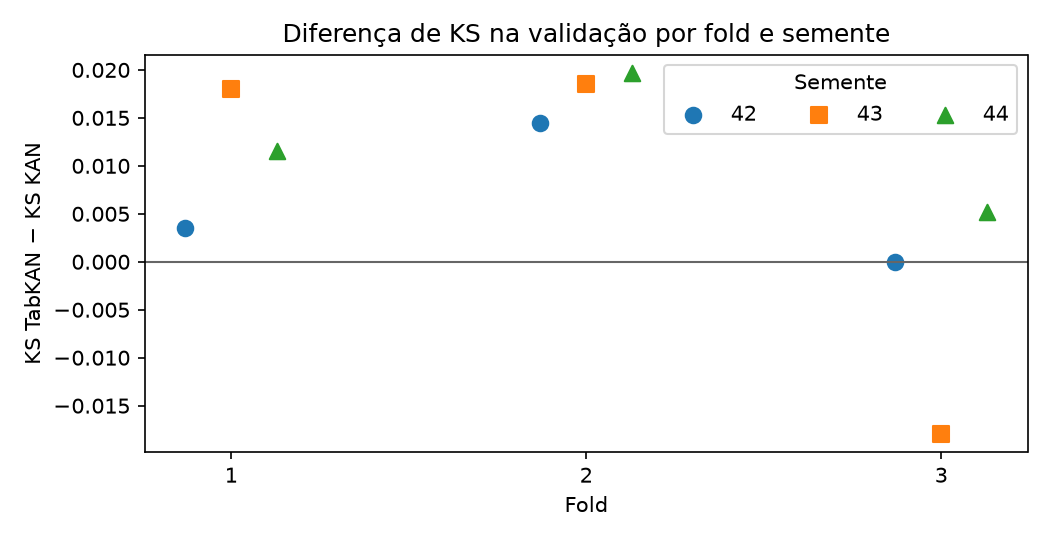

In [6]:
# A linha zero separa os ganhos da ChebyshevKAN dos ganhos da KAN.
import matplotlib.pyplot as plt

fig, eixo = plt.subplots(figsize=(7, 3.6))
for semente, deslocamento, marcador in [(42, -0.13, "o"), (43, 0, "s"), (44, 0.13, "^")]:
    serie = pares.xs(semente, level="semente")["delta"]
    eixo.scatter(serie.index + deslocamento, serie, marker=marcador, s=55, label=str(semente))
eixo.axhline(0, color="0.4", linewidth=1)
eixo.set(xticks=[1, 2, 3], xlabel="Fold", ylabel="KS TabKAN − KS KAN",
         title="Diferença de KS na validação por fold e semente")
eixo.legend(title="Semente", ncol=3)
fig.tight_layout()
arquivo = cfg.REPORTS_FIGURES / "09_tabkan_delta_ks_sementes.png"
fig.savefig(arquivo, dpi=150)
plt.show()

### Resultado das repetições

Nas sementes 42, 43 e 44, o KS médio foi 0.5183 para a KAN e 0.5264 para a ChebyshevKAN (diferença +0.0081). A ChebyshevKAN obteve KS maior em 7 pares, menor em 1 e empatou em 1, considerando a precisão numérica. O gráfico permite verificar se a direção da diferença se mantém dentro de cada fold. A conclusão se restringe a estas configurações e partições.

## E1 - ChebyshevKAN-Mixer

Misturar atributos e canais melhora o KS em relação à ChebyshevKAN simples? A referência externa é o [Mixer do TabKAN](https://github.com/aseslamian/TabKAN). Aqui usamos uma adaptação local compacta: um bloco, dois canais por atributo e largura interna 4 para limitar o custo em CPU. A projeção inicial é compartilhada entre atributos. O primeiro par de camadas de Chebyshev combina atributos dentro de cada canal; o segundo combina canais dentro de cada atributo. Cada par recebe dados normalizados e soma sua saída à representação anterior. A média por atributo alimenta a saída binária.

Mantemos grau 3, otimizador, lotes e parada antecipada da E0. Para comparar tempos, medimos novamente as três arquiteturas no mesmo processo, em CPU com uma thread. O tempo cobre o ajuste e a geração dos escores. O KS do fold 1 orienta a escolha; os outros folds mostram sua estabilidade.

In [7]:
# Mede as três redes sob as mesmas condições, em treino e validação.
from src.tabkan import criar_mixer

config_mixer = dict(config, largura=4, canais=2)
config_kan = {k: v for k, v in config.items() if k != "grau"}
config_kan["intervalos"] = 3
modelos = [("KAN", criar_spline, config_kan), ("ChebyshevKAN", criar_chebyshev, config),
           ("Mixer", criar_mixer, config_mixer)]
medicoes, resultados_mixer = [], []
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    for nome, fabrica, parametros in modelos:
        rede = fabrica(dados["treino"][0].shape[1], parametros)
        tamanho = sum(p.numel() for p in rede.parameters())
        for semente in (42, 43, 44):
            scores, historia, epoca, segundos = ajustar(dados, parametros, semente, fabrica)
            detalhes = dict(parametros, parametros_treinaveis=tamanho, melhor_epoca=epoca,
                            epocas_rodadas=len(historia))
            registro = evaluate_sets("tabkan" if nome != "KAN" else "kan", "neural", fold, scores,
                                     hiperparametros=detalhes, etapa="E1_mixer" if nome == "Mixer" else "E0_baseline",
                                     semente=semente)
            ks_validacao = registro.loc[registro.conjunto == "validacao", "ks"].item()
            medicoes.append(dict(modelo=nome, fold=fold, semente=semente, ks=ks_validacao,
                                 parametros=tamanho, segundos=segundos))
            if nome == "Mixer":
                resultados_mixer.append(registro)
save_results(pd.concat(resultados_mixer, ignore_index=True))
custos = pd.DataFrame(medicoes)
custos.to_csv(cfg.REPORTS_TABLES / "09_mixer_comparacao.csv", index=False)

In [8]:
# Emparelha os modelos antes de calcular as diferenças de validação.
pares_mixer = custos.pivot(index=["fold", "semente"], columns="modelo", values="ks")
assert pares_mixer.shape == (9, 3) and pares_mixer.notna().all().all()
pares_mixer["Mixer menos ChebyshevKAN"] = pares_mixer["Mixer"] - pares_mixer["ChebyshevKAN"]
print(pares_mixer.round(4).to_string())
print(custos.groupby("modelo").agg(ks_medio=("ks", "mean"), tempo_mediano_s=("segundos", "median"),
                                  parametros=("parametros", "first")).round(4).to_string())

modelo        ChebyshevKAN     KAN   Mixer  Mixer menos ChebyshevKAN
fold semente                                                        
1    42             0.5078  0.5043  0.1316                   -0.3762
     43             0.5200  0.5020  0.1316                   -0.3884
     44             0.5113  0.4997  0.1316                   -0.3797
2    42             0.5302  0.5157  0.0708                   -0.4594
     43             0.5348  0.5162  0.0708                   -0.4640
     44             0.5354  0.5157  0.0708                   -0.4646
3    42             0.5386  0.5386  0.1188                   -0.4197
     43             0.5217  0.5397  0.1188                   -0.4029
     44             0.5380  0.5328  0.1188                   -0.4191
              ks_medio  tempo_mediano_s  parametros
modelo                                             
ChebyshevKAN    0.5264           0.5888        1640
KAN             0.5183           2.7071        1241
Mixer           0.1071           

### Resultado da E1

O Mixer atingiu KS médio de 0.1071, frente a 0.5264 da ChebyshevKAN e 0.5183 da KAN. No fold 1, a diferença média Mixer menos ChebyshevKAN foi -0.3814. O Mixer superou a ChebyshevKAN em 0 dos nove pares. Esta comparação avalia as configurações completas, incluindo largura, normalização e agregação.

## E2 - O que acontece ao retirar a primeira LayerNorm?

Na E1, o KS coincidiu com o de um escore simples, o negativo da média dos atributos. Com dois canais, quando a diferença entre eles mantém o sinal e é grande em relação à tolerância numérica, a primeira normalização produz valores próximos dos mesmos dois níveis. O ramo residual ainda transmite a entrada. A hipótese é que isso fez o escore depender quase exclusivamente da média dos atributos.

A E2 substitui apenas a primeira normalização pela identidade. A segunda normalização, a largura 4, os dois canais, o grau 3 e o protocolo de treino seguem a E1. Comparamos o KS de validação nos mesmos nove pares e examinamos os logits no fold 1, semente 42.

In [9]:
# Treina a ablação e guarda os escores do par escolhido para o diagnóstico.
config_e2 = dict(config_mixer, normalizar_atributos=False)
linhas_e2 = []
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    entradas = dados["treino"][0].shape[1]
    tamanho = sum(p.numel() for p in criar_mixer(entradas, config_e2).parameters())
    for semente in (42, 43, 44):
        scores, historia, epoca, segundos = ajustar(dados, config_e2, semente, criar_mixer)
        detalhes = dict(config_e2, parametros_treinaveis=tamanho, melhor_epoca=epoca,
                        epocas_rodadas=len(historia), segundos=segundos)
        linhas_e2.append(evaluate_sets("tabkan", "neural", fold, scores,
                                       etapa="E2_sem_norm_atributos", semente=semente,
                                       hiperparametros=detalhes))
        if (fold, semente) == (1, 42):
            prob_e2 = scores["validacao"][1]
            dados_figura = dados
save_results(pd.concat(linhas_e2, ignore_index=True))

In [10]:
# Junta os resultados históricos por fold e semente.
bases = pd.read_csv(cfg.REPORTS_TABLES / "09_mixer_comparacao.csv")
comparacao_e2 = bases.pivot(index=["fold", "semente"], columns="modelo", values="ks")
e2 = pd.concat(linhas_e2).query("conjunto == 'validacao'").set_index(["fold", "semente"])
comparacao_e2["Mixer E2"] = e2["ks"]
assert comparacao_e2.shape == (9, 4) and comparacao_e2.notna().all().all()
print(comparacao_e2.round(4).to_string())
print(comparacao_e2.mean().round(4).to_string())

modelo        ChebyshevKAN     KAN   Mixer  Mixer E2
fold semente                                        
1    42             0.5078  0.5043  0.1316    0.5136
     43             0.5200  0.5020  0.1316    0.5055
     44             0.5113  0.4997  0.1316    0.5009
2    42             0.5302  0.5157  0.0708    0.5249
     43             0.5348  0.5162  0.0708    0.5220
     44             0.5354  0.5157  0.0708    0.5261
3    42             0.5386  0.5386  0.1188    0.5177
     43             0.5217  0.5397  0.1188    0.5223
     44             0.5380  0.5328  0.1188    0.5159
modelo
ChebyshevKAN    0.5264
KAN             0.5183
Mixer           0.1071
Mixer E2        0.5166


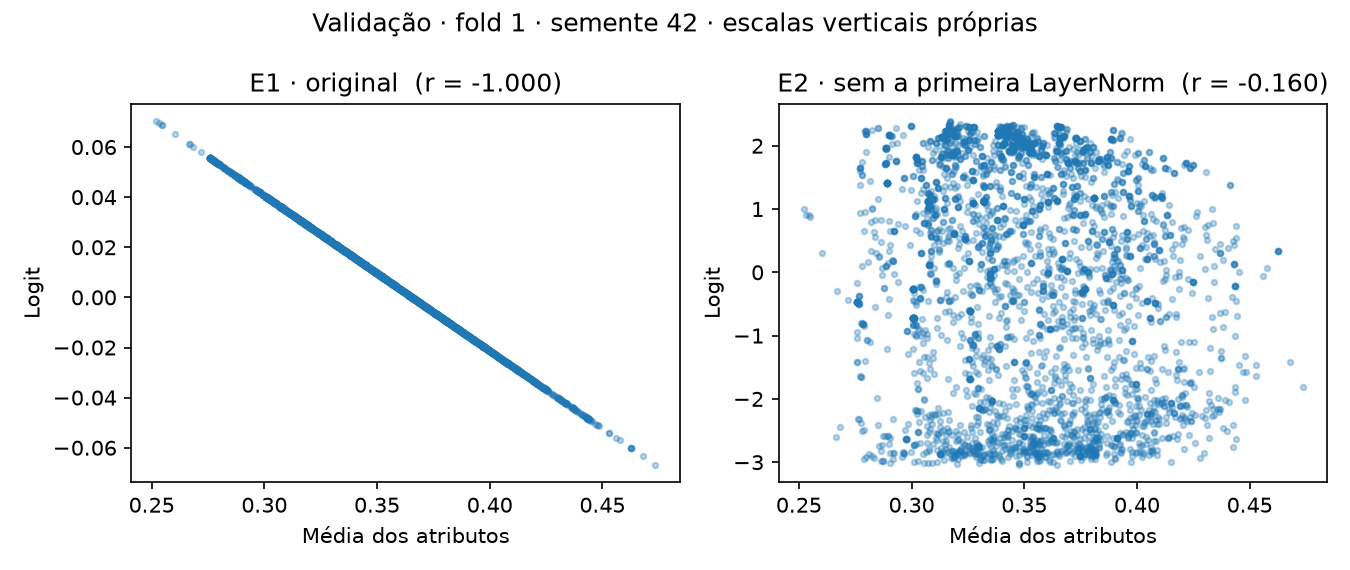

In [11]:
# Reconstrói os logits a partir das probabilidades dos melhores checkpoints.
import numpy as np
import matplotlib.pyplot as plt

scores_e1, _, _, _ = ajustar(dados_figura, config_mixer, 42, criar_mixer)
media_x = dados_figura["validacao"][0].mean(axis=1)
fig_e2, eixos = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True)
for eixo, nome, prob in zip(eixos, ["E1 · original", "E2 · sem a primeira LayerNorm"],
                            [scores_e1["validacao"][1], prob_e2]):
    prob = prob.astype(float)
    assert ((prob > 0) & (prob < 1)).all()
    logits = np.log(prob) - np.log1p(-prob)
    r = np.corrcoef(media_x, logits)[0, 1]
    eixo.scatter(media_x, logits, s=7, alpha=0.3)
    eixo.set(title=f"{nome}  (r = {r:.3f})", xlabel="Média dos atributos", ylabel="Logit")
fig_e2.suptitle("Validação · fold 1 · semente 42 · escalas verticais próprias")
fig_e2.tight_layout()
figura_e2 = cfg.REPORTS_FIGURES / "09_mixer_logits_e1_e2.png"
fig_e2.savefig(figura_e2, dpi=150)
plt.show()

### Resultado da E2

Retirar a primeira LayerNorm elevou o KS médio do Mixer de 0.1071 para 0.5166. A KAN obteve 0.5183 e a ChebyshevKAN 0.5264. A E2 superou a ChebyshevKAN em 2 dos nove pares. No fold 1, a diferença média E2 menos ChebyshevKAN foi -0.0064. No diagnóstico visual, clientes com médias semelhantes passam a receber logits distintos na E2. A recuperação caracteriza o efeito desta ablação no Mixer compacto.

## Avaliação final em teste

Fixamos a KAN de três intervalos e a ChebyshevKAN de grau 3, ambas com largura 10. O Mixer encerrou sua participação na ablação de validação. Repetimos os ajustes com as sementes 42–44 e comparamos o KS de validação aos registros da E0 para verificar a reprodução de cada par. Os pesos da época escolhida na validação pontuam o teste original de cada fold. A prevalência de churn é de aproximadamente 26,5%.

A curva de ganhos ordena clientes por risco e mede a fração dos cancelamentos observados entre os primeiros q% da carteira. Interpolamos dentro de cada grupo de escores empatados, o que equivale à captura esperada sob desempate aleatório. Calculamos uma curva por fold e semente, depois a média das nove curvas. Isso mantém cada ordenação dentro de sua própria população de teste.

In [12]:
# Reproduz as referências e mede a captura nas partições originais de teste.
import numpy as np
from src.metrics import ks_score

config_final_kan = {k: v for k, v in config.items() if k != "grau"}
config_final_kan["intervalos"] = 3
grade = np.arange(101) / 100
registros, ganhos = [], []
for nome, fabrica, parametros in [("kan", criar_spline, config_final_kan),
                                  ("tabkan", criar_chebyshev, config)]:
    anterior = pd.read_csv(cfg.REPORTS_TABLES / f"resultados_{nome}.csv")
    referencia = anterior.query("etapa == 'E0_baseline' and conjunto == 'validacao' and variante == 'neural'").set_index(["fold", "semente"])
    por_modelo = []
    for fold in range(1, cfg.K_FOLDS + 1):
        dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
        xt, yt = load_preprocessed(fold, "teste", "neural")
        for semente in (42, 43, 44):
            scores, historia, epoca, _ = ajustar(dados, parametros, semente, fabrica, x_teste=xt)
            assert np.isclose(ks_score(*scores["validacao"]), referencia.loc[(fold, semente), "ks"], atol=1e-6)
            prob = scores.pop("prob_teste")
            scores["teste"] = (yt, prob)
            res = evaluate_sets(nome, "neural", fold, scores, etapa="final_teste", semente=semente,
                                hiperparametros=dict(parametros, melhor_epoca=epoca, epocas_rodadas=len(historia)))
            por_modelo.append(res)
            # Os limites de cada grupo empatado preservam todos os clientes.
            grupos = pd.DataFrame({"p": prob, "y": np.asarray(yt).ravel()}).groupby("p", sort=True).y.agg(["size", "sum"]).iloc[::-1]
            x = np.r_[0, grupos["size"].cumsum() / len(prob)]
            y = np.r_[0, grupos["sum"].cumsum() / grupos["sum"].sum()]
            ganhos.append(pd.DataFrame({"modelo": nome, "fold": fold, "semente": semente,
                                        "fracao": grade, "captura": np.interp(grade, x, y)}))
    bloco = pd.concat(por_modelo, ignore_index=True)
    save_results(bloco)
    registros.append(bloco)
teste = pd.concat(registros).query("conjunto == 'teste'")
curvas = pd.concat(ganhos, ignore_index=True)
curvas.to_csv(cfg.REPORTS_TABLES / "09_ganhos_teste.csv", index=False)
print(teste.groupby(["fold", "modelo"]).ks.mean().unstack().round(4).to_string())
print(teste.groupby("modelo")[["ks", "auroc"]].mean().round(4).to_string())
print(curvas.query("fracao == 0.2").groupby("modelo").captura.mean().round(4).to_string())

modelo     kan  tabkan
fold                  
1       0.5128  0.5219
2       0.5450  0.5550
3       0.5335  0.5372
            ks   auroc
modelo                
kan     0.5304  0.8394
tabkan  0.5380  0.8415
modelo
kan       0.4927
tabkan    0.4971


In [13]:
# A diagonal representa uma campanha com priorização aleatória.
import matplotlib.pyplot as plt

media_ganhos = curvas.groupby(["fracao", "modelo"]).captura.mean().unstack()
ax = media_ganhos.rename(columns={"kan": "KAN", "tabkan": "ChebyshevKAN"}).plot()
ax.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
ax.axvline(0.2, color="gray", linewidth=0.8)
ax.set(xlabel="Fração da carteira priorizada", ylabel="Fração dos cancelamentos capturados")
ax.legend()
ax.figure.tight_layout()
ax.figure.savefig(cfg.REPORTS_FIGURES / "09_ganhos_teste.png", dpi=150)
plt.show()

### Resultado final

No teste, o KS médio foi 0,5304 para a KAN e 0,5380 para a ChebyshevKAN. Priorizando 20% da carteira, as capturas médias foram 49.3% e 49.7%, respectivamente. O ganho mede concentração de risco. O efeito de uma oferta sobre cancelamentos exigiria observar a intervenção.

## E3 - Média ponderada no Mixer

Após a avaliação das referências, retomamos o desenvolvimento usando treino e validação. A E2 agrega as 40 posições com o mesmo peso. A E3 aprende 40 logits globais, normalizados por softmax e compartilhados pelos dois canais. Cada posição já recebeu informação das demais; seu peso descreve a agregação interna. A inicialização em zero recupera a média simples.

O critério principal é a diferença de KS de validação entre E3 e E2, pareada por fold e semente. O fold 1 orienta a decisão e os demais mostram a estabilidade.

In [14]:
# Confere a equivalência inicial com os mesmos pesos e entradas reais.
config_e3 = dict(config_e2, pooling_ponderado=True)
amostra = load_preprocessed(1, "treino", "neural")[0].iloc[:64]
x_inicial = torch.tensor(amostra.to_numpy(), dtype=torch.float32)
torch.manual_seed(42)
controle = criar_mixer(amostra.shape[1], config_e2)
torch.manual_seed(42)
ponderado = criar_mixer(amostra.shape[1], config_e3)
torch.testing.assert_close(ponderado(x_inicial), controle(x_inicial))
ponderado(x_inicial).sum().backward()
assert ponderado.logits_pooling.grad.abs().sum().item() > 0

In [15]:
# Treina a partir de pesos novos em cada par e registra apenas treino e validação.
linhas_e3 = []
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    for semente in (42, 43, 44):
        scores, historia, epoca, segundos = ajustar(dados, config_e3, semente, criar_mixer)
        parametros = dict(config_e3, melhor_epoca=epoca, epocas_rodadas=len(historia),
                          segundos=segundos, parametros_treinaveis=sum(p.numel() for p in ponderado.parameters()))
        linhas_e3.append(evaluate_sets("tabkan", "neural", fold, scores, etapa="E3_pooling_ponderado",
                                       semente=semente, hiperparametros=parametros))
resultado_e3 = pd.concat(linhas_e3, ignore_index=True)
save_results(resultado_e3)

In [16]:
# Compara somente a validação das quatro configurações nos mesmos nove pares.
colunas_e3 = {}
for modelo, etapa, rotulo in [("kan", "E0_baseline", "KAN"), ("tabkan", "E0_baseline", "ChebyshevKAN"),
                              ("tabkan", "E2_sem_norm_atributos", "Mixer E2"),
                              ("tabkan", "E3_pooling_ponderado", "Mixer E3")]:
    tabela = pd.read_csv(cfg.REPORTS_TABLES / f"resultados_{modelo}.csv")
    linhas = tabela.query("conjunto == 'validacao' and variante == 'neural' and etapa == @etapa")
    colunas_e3[rotulo] = linhas.set_index(["fold", "semente"]).ks
comparacao_e3 = pd.DataFrame(colunas_e3).sort_index()
assert comparacao_e3.shape == (9, 4) and comparacao_e3.notna().all().all()
comparacao_e3["delta"] = comparacao_e3["Mixer E3"] - comparacao_e3["Mixer E2"]
print(comparacao_e3.round(4).to_string())
print(comparacao_e3.mean().round(4).to_string())

                 KAN  ChebyshevKAN  Mixer E2  Mixer E3   delta
fold semente                                                  
1    42       0.5043        0.5078    0.5136    0.5096 -0.0041
     43       0.5020        0.5200    0.5055    0.5049 -0.0006
     44       0.4997        0.5113    0.5009    0.5067  0.0058
2    42       0.5157        0.5302    0.5249    0.5215 -0.0035
     43       0.5162        0.5348    0.5220    0.5232  0.0012
     44       0.5157        0.5354    0.5261    0.5255 -0.0006
3    42       0.5386        0.5386    0.5177    0.5154 -0.0023
     43       0.5397        0.5217    0.5223    0.5287  0.0064
     44       0.5328        0.5380    0.5159    0.5287  0.0128
KAN             0.5183
ChebyshevKAN    0.5264
Mixer E2        0.5166
Mixer E3        0.5182
delta           0.0017


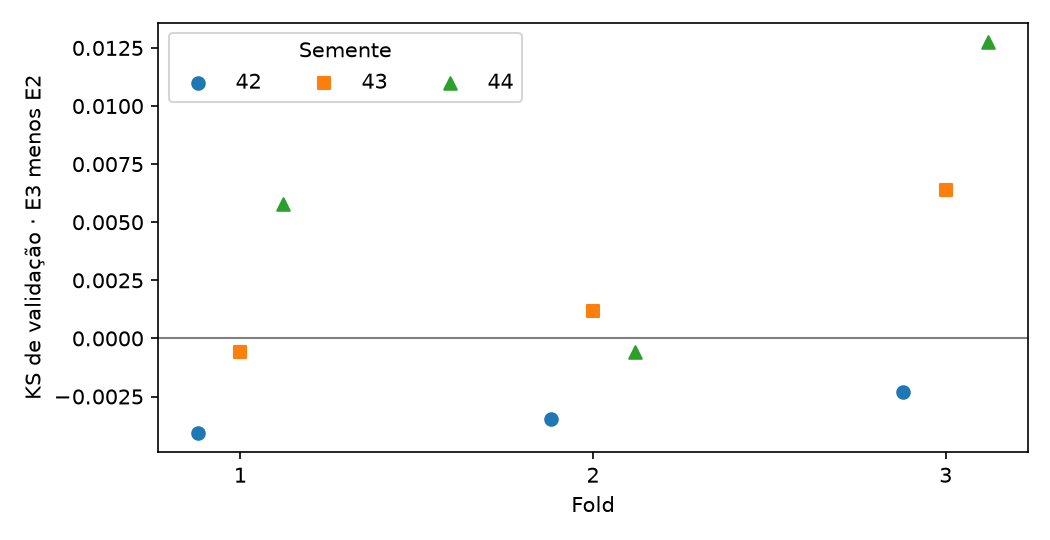

In [17]:
# O zero marca o mesmo KS para os dois métodos de agregação.
import matplotlib.pyplot as plt

fig, eixo = plt.subplots(figsize=(7, 3.6))
for semente, dx, marcador in [(42, -0.12, "o"), (43, 0, "s"), (44, 0.12, "^")]:
    serie = comparacao_e3.xs(semente, level="semente").delta
    eixo.scatter(serie.index + dx, serie, marker=marcador, label=str(semente))
eixo.axhline(0, color="gray", linewidth=1)
eixo.set(xticks=[1, 2, 3], xlabel="Fold", ylabel="KS de validação · E3 menos E2")
eixo.legend(title="Semente", ncol=3)
fig.tight_layout()
figura_e3 = cfg.REPORTS_FIGURES / "09_mixer_pooling_delta_ks.png"
fig.savefig(figura_e3, dpi=150)
plt.show()

### Resultado da E3

O KS médio passou de 0,5166 na E2 para 0,5182 na E3. A E3 melhorou em 4 dos nove pares. No fold 1, a diferença média foi +0,0004. A ChebyshevKAN obteve 0,5264.

## E4 - Busca Optuna na ChebyshevKAN

Quanto o ajuste de hiperparâmetros acrescenta à configuração original na variante neural? Fixamos Adam, perda, teto de épocas e parada antecipada. O TPE avalia 100 tentativas no fold 1 com semente 42. A primeira reproduz a E0. Variamos largura (5–64, escala logarítmica), grau (1–5), taxa (0,0001–0,01, escala logarítmica) e lote (32, 64, 128 ou 256).

O checkpoint minimiza a perda de validação; o ranking maximiza o KS. Reavaliamos as cinco configurações distintas de maior KS com três sementes e congelamos a finalista de maior média no fold 1, usando a ordem das tentativas para resolver empates. A E0 continua como controle para a decisão de adoção.

In [18]:
# Inclui a referência no orçamento e preserva as partições do estudo.
import optuna
from src.chebyshev_busca import buscar_chebyshev
from src.metrics import ks_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
def dados_busca(fold):
    return {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}

dados_f1 = dados_busca(1)
tentativas = buscar_chebyshev(dados_f1, config, raiz)
chaves = ["largura", "grau", "lr", "lote"]
finalistas = tentativas.drop_duplicates(chaves).head(5)
assert len(tentativas) == 100 and len(finalistas) == 5
print(finalistas[["trial", "ks", *chaves]].to_string(index=False))

 trial       ks  largura  grau       lr  lote
    97 0.532754        6     5 0.000533    32
    72 0.531594        6     5 0.000548    32
    81 0.529275        6     5 0.000579    32
    96 0.529275        6     5 0.000580    32
    95 0.528116        6     5 0.000567    32


In [19]:
# Reavalia cada finalista nas três sementes antes de abrir os outros folds.
configuracoes, notas = {}, []
for linha in finalistas.itertuples():
    parametros = dict(config, largura=linha.largura, grau=linha.grau, lr=linha.lr, lote=linha.lote)
    configuracoes[linha.trial] = parametros
    for semente in (42, 43, 44):
        scores, _, _, _ = ajustar(dados_f1, parametros, semente, criar_chebyshev)
        notas.append(dict(trial=linha.trial, semente=semente, ks=ks_score(*scores["validacao"])))
notas = pd.DataFrame(notas)
notas.to_csv(cfg.REPORTS_TABLES / "09_chebyshev_finalistas.csv", index=False)
ranking = notas.groupby("trial").ks.mean().sort_values(ascending=False, kind="stable")
vencedora = configuracoes[ranking.index[0]]
print(ranking.to_string())
print(vencedora)

trial
72    0.521739
97    0.521353
81    0.520193
96    0.520193
95    0.520000
{'largura': 6, 'grau': 5, 'lr': 0.000548164812907324, 'lote': 32, 'max_epocas': 120, 'paciencia': 15, 'min_delta': 0.0001}


In [20]:
# Compara a configuração congelada com as referências pareadas.
registros_e4 = []
for fold in (1, 2, 3):
    dados = dados_busca(fold)
    for semente in (42, 43, 44):
        scores, historia, epoca, _ = ajustar(dados, vencedora, semente, criar_chebyshev)
        parametros = dict(vencedora, melhor_epoca=epoca, epocas_rodadas=len(historia))
        registros_e4.append(evaluate_sets("tabkan", "neural", fold, scores, etapa="E4_busca_chebyshev",
                                          semente=semente, hiperparametros=parametros))
e4 = pd.concat(registros_e4, ignore_index=True)
save_results(e4)
pares_e4 = {}
for nome, modelo, etapa in [("KAN", "kan", "E0_baseline"), ("Chebyshev E0", "tabkan", "E0_baseline"),
                            ("Chebyshev E4", "tabkan", "E4_busca_chebyshev")]:
    tabela = pd.read_csv(cfg.REPORTS_TABLES / f"resultados_{modelo}.csv")
    val = tabela.query("variante == 'neural' and etapa == @etapa and conjunto == 'validacao'")
    pares_e4[nome] = val.set_index(["fold", "semente"]).ks
pares_e4 = pd.DataFrame(pares_e4)
assert pares_e4.shape == (9, 3) and pares_e4.notna().all().all()
pares_e4["delta"] = pares_e4["Chebyshev E4"] - pares_e4["Chebyshev E0"]
print(pares_e4.round(5).to_string())
print(pares_e4.groupby(level="fold").mean().round(5).to_string())
print(pares_e4.mean().round(5).to_string())

                  KAN  Chebyshev E0  Chebyshev E4    delta
fold semente                                              
1    42       0.50435       0.50783       0.53159  0.02377
     43       0.50203       0.52000       0.51826 -0.00174
     44       0.49971       0.51130       0.51536  0.00406
2    42       0.51566       0.53016       0.51276 -0.01740
     43       0.51624       0.53480       0.51392 -0.02088
     44       0.51566       0.53538       0.51102 -0.02436
3    42       0.53855       0.53855       0.52928 -0.00928
     43       0.53971       0.52174       0.51768 -0.00406
     44       0.53275       0.53797       0.53217 -0.00580
          KAN  Chebyshev E0  Chebyshev E4    delta
fold                                              
1     0.50203       0.51304       0.52174  0.00870
2     0.51585       0.53345       0.51257 -0.02088
3     0.53700       0.53275       0.52638 -0.00638
KAN             0.51830
Chebyshev E0    0.52642
Chebyshev E4    0.52023
delta          -0.00619


### Resultado da busca

A finalista selecionada usa largura 6, grau 5, taxa 0.000548165 e lote 32. A diferença média de KS em relação à E0 foi +0.0087 no fold de busca e -0.0062 nos nove pares. Os resultados são de validação.